# Flip state grids

The target grid for each flip state, drawn like the occupancy maps (arena on its side, low-y end on the left) but without the dashed middle row. Each grid shows only the cells that flip state's target can be in, with a bold line around them:

- **Flip 0**: cue at the low end, target in inner rows 0-3 (cells 0-11).
- **Flip 1**: cue at the high end, target in inner rows 5-8 (cells 15-26).
- **Flip 2**: no cue, target in any of the 27 cells.

Each grid is saved as a 1108 x 492 px PNG with a transparent background, for overlaying on video, to `output/slides_flip/`, with the camera frame filling the image. That stretches the arena's 1968 x 888 px frame by about 1.6% along its short axis.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Image, display

from src import config as cfg
from src.style import use_style

use_style(slides=True)
SLIDES_DIR = cfg.OUT_DIR / 'slides_flip'
SLIDES_DIR.mkdir(exist_ok=True)

SIZE_PX = (1108, 492)                                 # width (long axis), height
DPI = 200

TARGET_ROWS = {                                       # flip state: the inner rows (from the low-y end) its target can be in
    0: range(0, 4),
    1: range(5, cfg.INNER_ROWS),
    2: range(0, cfg.INNER_ROWS),
}

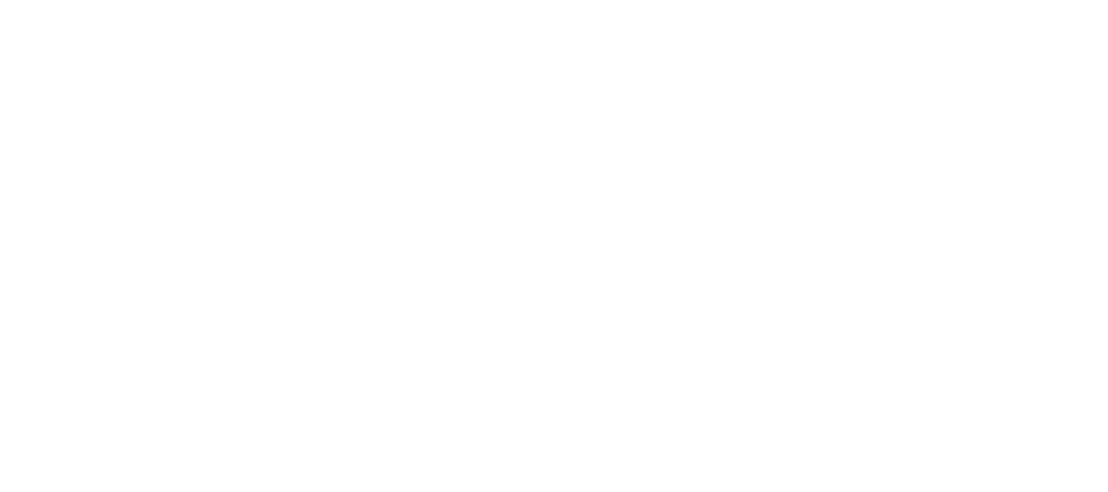

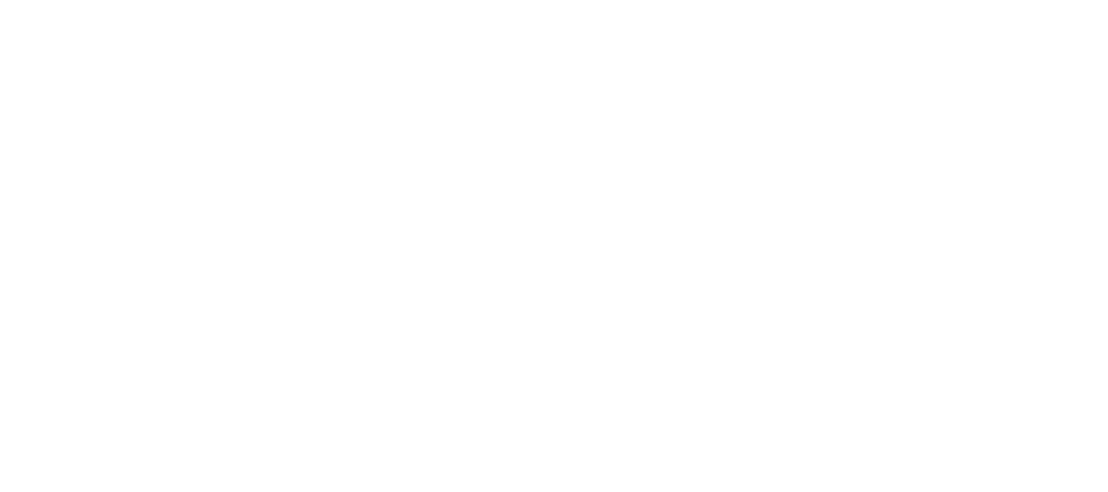

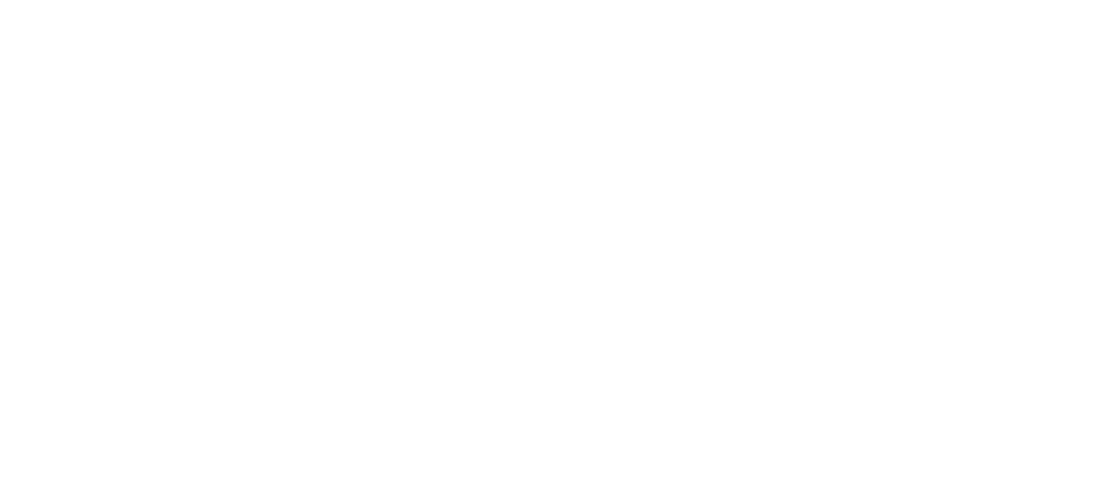

In [2]:
# cell edges as the maps draw them: integer cells, the last one running to the edge of the target grid
ROW_EDGES = np.r_[np.arange(1, cfg.GRID_ROWS - 1) * cfg.CELL_H, cfg.FRAME_H - cfg.CELL_H]
COL_EDGES = np.r_[np.arange(1, cfg.GRID_COLS - 1) * cfg.CELL_W, cfg.FRAME_W - cfg.CELL_W]

def flip_grid(flip):
    """One flip state's target cells, arena on its side and filling the whole figure; white lines on a transparent background."""
    W, H = SIZE_PX
    fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI)
    ax = fig.add_axes([0, 0, 1, 1])
    rows = TARGET_ROWS[flip]
    x0, x1 = ROW_EDGES[rows.start], ROW_EDGES[rows.stop]
    y0, y1 = COL_EDGES[0], COL_EDGES[-1]
    # target cells, faint
    for x in ROW_EDGES[rows.start + 1:rows.stop]:
        ax.plot([x] * 2, [y0, y1], color='white', lw=0.6, alpha=0.3)
    for y in COL_EDGES[1:-1]:
        ax.plot([x0, x1], [y] * 2, color='white', lw=0.6, alpha=0.3)
    # edge of the cells the target can be in, bold
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='white', lw=1))
    ax.annotate(f'flip state {flip}', xy=(0, 1), xycoords='axes fraction', xytext=(12, -12), textcoords='offset points',
                ha='left', va='top', color='white', fontsize=16)
    ax.set(xlim=(0, cfg.FRAME_H), ylim=(0, cfg.FRAME_W), aspect='auto')
    ax.axis('off')
    return fig

for flip in TARGET_ROWS:
    path = SLIDES_DIR / f'flip_grid_{flip}.png'
    fig = flip_grid(flip)
    fig.savefig(path, dpi=DPI, transparent=True)      # transparent, to overlay on video
    plt.close(fig)
    display(Image(filename=path))